# 02 · Modelagem e avaliação

**O que o modelo responde:** para uma empresa e um prazo de *t* meses, a probabilidade de ela
continuar ativa até o fim do prazo, S(t). O risco do consignado é 1 − S(t).

Este notebook mostra como cheguei ao modelo usado pelo agent:

1. Formulação: por que um modelo exponencial por partes
2. Comparação de alternativas, todas treinadas nos mesmos dados
3. Quanto cada fonte de dados acrescenta
4. O modelo final no conjunto de teste
5. Quando confiar (e quando não confiar) nas previsões
6. O que mais pesa no risco
7. Sensibilidade à definição de evento

**O modelo do agent é o produzido por** `python -m consig_risk.modeling.train` (artefato em
`artifacts/model/`). Este notebook carrega esse artefato para a avaliação final; as alternativas
são treinadas aqui só para comparação.

In [1]:
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from consig_risk.modeling import data as mdata
from consig_risk.modeling.artifact import RiskModel
from consig_risk.modeling.metrics import calibration_table, concordance, horizon_metrics
from consig_risk.modeling.models import (
    CoxBaseline,
    KaplanMeierBaseline,
    PiecewiseGBM,
    PiecewiseGLM,
    fit_categories,
)
from consig_risk.modeling.spec import EVALUATION_HORIZONS, LABELS

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
COHORT = Path("data/processed/cohort.parquet")

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "text.color": INK,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "lines.linewidth": 2,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "figure.dpi": 110,
    }
)


def resumo(nome: str, firms: pd.DataFrame, s: np.ndarray) -> dict:
    m = horizon_metrics(firms, s, EVALUATION_HORIZONS).set_index("horizonte")
    linha = {"modelo": nome, "C-index": concordance(firms, s[:, -1])}
    for h in EVALUATION_HORIZONS:
        linha[f"AUC {h}m"] = m.loc[h, "auc"]
    for h in EVALUATION_HORIZONS:
        linha[f"previsto/observado {h}m"] = (
            f"{100 * m.loc[h, 'risco_previsto_medio']:.1f}% / {100 * m.loc[h, 'risco_observado']:.1f}%"
        )
    linha["Brier skill 24m"] = m.loc[24, "brier_skill"]
    return linha

## 1. Formulação

**Evento:** a empresa sai da situação cadastral ativa (baixada, inapta, suspensa ou nula). Ver
EDA, seção 2.

**Por que sobrevivência, e não um classificador por prazo.** Um classificador "fecha em 24
meses?" exigiria um modelo por prazo, os prazos poderiam se contradizer (risco em 36 meses menor
que em 24) e "e se fossem 12 meses?" seria outro modelo. Um modelo de sobrevivência gera a curva
S(t) inteira: o veredito para um prazo, o prazo máximo e as perguntas de acompanhamento saem da
mesma curva, sempre coerentes.

**Por que exponencial por partes.** A EDA mostrou dois fatos que descartam o Cox clássico como
modelo final:

1. As inaptidões chegam em **lotes anuais** da Receita. Um modelo indexado pelo mês desde a
   origem aprenderia o calendário de 2023–2026, que não vale para um empréstimo que começa hoje.
2. As curvas por idade **se cruzam**: o efeito das features muda com o prazo, o que viola a
   hipótese de riscos proporcionais.

No modelo exponencial por partes, o acompanhamento de cada empresa é dividido em períodos (ano 1,
ano 2, ano 3 em diante). Dentro de cada período, o risco é uma **taxa mensal** que depende das
features e da **idade da empresa no início do período**. Com isso:

- o calendário dos lotes vira uma média dentro de cada período;
- o efeito de cada feature pode mudar de um período para outro (o modelo vê o período e a idade);
- para prazos além dos 41 meses observados, cada novo ano usa a idade atualizada da empresa.

**Estimação.** É uma regressão de Poisson com alvo `eventos / exposição` e peso `exposição`, o
que equivale a usar log(exposição) como offset. Compara-se uma versão linear (GLM) e uma com
árvores (LightGBM).

**Dados.** Os splits são baldes fixos do hash do CNPJ básico, então são reproduzíveis e
disjuntos: treino 20%, validação 5% (parada antecipada e escolha do modelo) e teste 10% (usado
uma única vez, na seção 4).

## 2. Comparação de alternativas

Para a comparação ser justa, todos os candidatos são treinados nos mesmos 5% de empresas e
avaliados no mesmo split de validação. O Cox é ajustado em 200 mil empresas porque o lifelines é
mais lento.

**Como ler as métricas:**

- **AUC** em cada horizonte: separação entre quem sai e quem fica até *t*. Não há censura antes de
  41 meses, então é a AUC comum de classificação.
- **Previsto/observado:** risco médio previsto contra a proporção observada. Mede calibração no
  agregado.
- **Brier skill:** quanto o erro quadrático melhora em relação a prever a taxa média para todos.
- **C-index:** concordância entre o risco previsto e o tempo até o evento.

In [2]:
t0 = time.time()
treino = mdata.load_cohort(COHORT, mdata.TRAIN, limit_buckets=50)  # 5%
valid = mdata.load_cohort(COHORT, mdata.VALIDATION)
cats = fit_categories(treino)
p_treino, p_valid = mdata.expand_pieces(treino), mdata.expand_pieces(valid)
print(
    f"treino: {len(treino):,} empresas ({len(p_treino):,} linhas empresa×período); validação: {len(valid):,}"
)

candidatos = {}
km = KaplanMeierBaseline().fit(treino)
candidatos[km.name] = km.survival(valid, EVALUATION_HORIZONS)
cox = CoxBaseline().fit(treino.iloc[:200_000], cats)
candidatos[cox.name] = cox.survival(valid, EVALUATION_HORIZONS)
glm = PiecewiseGLM().fit(p_treino, cats)
candidatos[glm.name] = glm.survival(valid, EVALUATION_HORIZONS)
gbm5 = PiecewiseGBM().fit(p_treino, cats, p_valid)
candidatos[gbm5.name] = gbm5.survival(valid, EVALUATION_HORIZONS)
comparacao = pd.DataFrame([resumo(n, valid, s) for n, s in candidatos.items()]).set_index("modelo")
display(comparacao)
print(f"tempo: {time.time() - t0:.0f}s")

treino: 476,635 empresas (1,337,362 linhas empresa×período); validação: 477,026


,C-index,AUC 12m,AUC 24m,AUC 36m,AUC 41m,previsto/observado 12m,previsto/observado 24m,previsto/observado 36m,previsto/observado 41m,Brier skill 24m
modelo,,,,,,,,,,
Kaplan-Meier (sem features),0.500,0.500,0.500,0.500,0.500,6.6% / 6.6%,12.8% / 12.9%,16.4% / 16.4%,24.3% / 24.3%,-0.000
Cox de riscos proporcionais,0.668,0.668,0.679,0.669,0.691,5.5% / 6.6%,10.4% / 12.9%,14.5% / 16.4%,20.1% / 24.3%,0.039
Exponencial por partes + Poisson linear (GLM),0.687,0.687,0.702,0.692,0.714,6.7% / 6.6%,13.0% / 12.9%,21.1% / 16.4%,24.1% / 24.3%,0.065
Exponencial por partes + LightGBM (Poisson),0.717,0.737,0.740,0.726,0.748,6.6% / 6.6%,13.1% / 12.9%,21.1% / 16.4%,24.0% / 24.3%,0.099


tempo: 41s


### Por que não o Cox: teste de riscos proporcionais

O teste de Schoenfeld (lifelines) verifica, covariável por covariável, se o efeito é constante
no tempo. Rodado numa amostra de 30 mil empresas, porque o teste é caro (o poder do teste é
limitado nesse tamanho).

In [3]:
from lifelines.statistics import proportional_hazard_test

amostra_ph = treino.sample(30_000, random_state=0)
cox_ph = CoxBaseline().fit(amostra_ph, cats)
design = cox_ph.design(amostra_ph)
design["duracao_meses"] = amostra_ph["duracao_meses"].to_numpy()
design["evento"] = amostra_ph["evento"].to_numpy()
ph_todos = proportional_hazard_test(cox_ph.cph, design, time_transform="rank").summary
ph = ph_todos.sort_values("p").head(8)[["test_statistic", "p"]]
ph.index = [str(i) for i in ph.index]
display(ph)
print(
    f"covariáveis com efeito não constante no tempo (p < 0,01): {(ph_todos['p'] < 0.01).sum()} de {len(ph_todos)}"
)

,test_statistic,p
uf_EX,98.412,0.000
grupo_natureza_3,29.792,0.000
cnae_secao_K,20.908,0.000
capital_social,10.185,0.001
porte_01,9.879,0.002
tem_socio_pj,9.251,0.002
porte_05,5.869,0.015
n_socios,5.316,0.021


covariáveis com efeito não constante no tempo (p < 0,01): 6 de 71


**Leitura da comparação:**

- O **Kaplan-Meier** acerta o risco médio por construção, mas não distingue empresas (AUC 0,5). É
  o piso.
- O **Cox** é o pior entre os modelos com features: separa menos e **subestima o risco** em todos
  os horizontes (20% previsto contra 24% observado em 41 meses). O teste de Schoenfeld rejeita a
  proporcionalidade para algumas covariáveis (porte, capital, sócio PJ, setor financeiro, entidades
  sem fins lucrativos), mas o argumento decisivo é prático: ele mede o tempo desde a origem, então
  o calendário dos lotes entra na curva base, e não há como avançar a idade da empresa para
  extrapolar prazos longos.
- O **GLM por partes** é bem calibrado e interpretável, mas separa menos que o GBM.
- O **GBM por partes** tem a melhor separação em todos os horizontes, com a mesma calibração do
  GLM. É o escolhido.
- Nos dois modelos por partes, o desvio em 36 meses é o efeito do calendário dos lotes (seção 4);
  aos 41 meses o previsto bate com o observado.

## 3. Quanto cada fonte de dados acrescenta

O case pede para documentar o que foi usado e por quê. Aqui está a evidência: o mesmo GBM, nos
mesmos dados, com e sem cada fonte complementar. Remover uma fonte é fixar as features dela num
valor constante, o que retira toda a informação sem mudar o resto do pipeline.

In [4]:
ECF = ["regime_tributario"]
PGFN = [
    "divida_fgts",
    "divida_previdenciaria",
    "divida_nao_previdenciaria",
    "divida_ajuizada",
    "n_inscricoes_divida",
    "valor_divida",
    "meses_desde_ultima_inscricao",
]


def sem(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    out = df.copy()
    for c in cols:
        out[c] = False if out[c].dtype == bool else (None if out[c].dtype == object else np.nan)
    return out


variantes = {
    "só Receita (CNPJ, Simples, sócios)": ECF + PGFN,
    "Receita + regime tributário (ECF)": PGFN,
    "Receita + dívida ativa (PGFN)": ECF,
    "todas as fontes": [],
}
linhas = []
for nome, remover in variantes.items():
    tr, va = sem(treino, remover), sem(valid, remover)
    m = PiecewiseGBM().fit(mdata.expand_pieces(tr), cats, mdata.expand_pieces(va))
    linhas.append(resumo(nome, va, m.survival(va, EVALUATION_HORIZONS)))
ablacao = pd.DataFrame(linhas).set_index("modelo")[
    ["C-index", "AUC 12m", "AUC 24m", "AUC 36m", "Brier skill 24m"]
]
display(ablacao)

,C-index,AUC 12m,AUC 24m,AUC 36m,Brier skill 24m
modelo,,,,,
"só Receita (CNPJ, Simples, sócios)",0.691,0.704,0.709,0.700,0.074
Receita + regime tributário (ECF),0.708,0.727,0.730,0.718,0.089
Receita + dívida ativa (PGFN),0.704,0.719,0.724,0.712,0.086
todas as fontes,0.717,0.737,0.740,0.726,0.099


Cada fonte complementar melhora o modelo, e as duas juntas mais ainda: o regime tributário (ECF)
acrescenta cerca de 0,02 de AUC, a dívida ativa (PGFN) cerca de 0,015, e juntas cerca de 0,03
sobre o modelo só com dados da Receita. O ganho é modesto, mas consistente em todos os horizontes,
e as duas fontes são baratas (públicas, por CNPJ, com data).

## 4. O modelo final no conjunto de teste

In [5]:
modelo = RiskModel.load(Path("artifacts/model"))
meta = modelo.metadata
print(
    f"{meta['modelo']}: {modelo.gbm.booster.num_trees()} árvores, treinado em {meta['empresas_treino']:,} empresas"
)

teste = mdata.load_cohort(COHORT, mdata.TEST)
s_teste = modelo.survival(teste, EVALUATION_HORIZONS)
metricas_teste = horizon_metrics(teste, s_teste, EVALUATION_HORIZONS)
print(f"teste: {len(teste):,} empresas · C-index {concordance(teste, s_teste[:, -1]):.3f}")
display(metricas_teste.set_index("horizonte"))

Exponencial por partes + LightGBM (Poisson): 1114 árvores, treinado em 1,907,618 empresas


teste: 954,274 empresas · C-index 0.721


,auc,brier,brier_skill,risco_previsto_medio,risco_observado
horizonte,,,,,
12,0.743,0.057,0.078,0.067,0.066
24,0.745,0.101,0.105,0.131,0.129
36,0.730,0.127,0.079,0.211,0.164
41,0.751,0.156,0.154,0.240,0.243


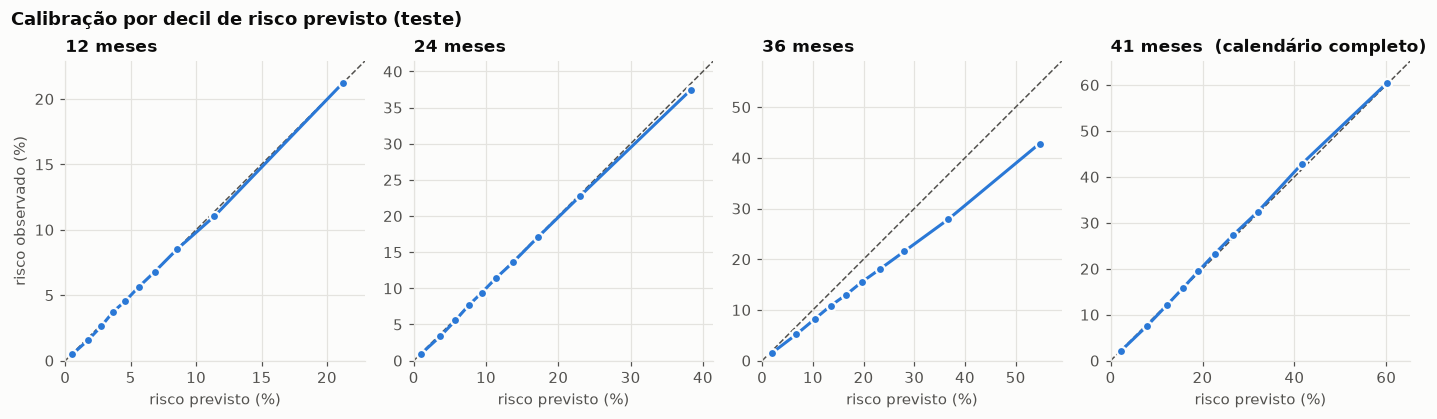

In [6]:
cal = calibration_table(teste, s_teste, EVALUATION_HORIZONS)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, h in zip(axes, EVALUATION_HORIZONS):
    c = cal[cal.horizonte == h]
    lim = max(c.previsto.max(), c.observado.max()) * 100 * 1.08
    ax.plot([0, lim], [0, lim], color=INK2, linestyle="--", linewidth=1)
    ax.plot(
        100 * c.previsto,
        100 * c.observado,
        "o-",
        color=BLUE,
        markersize=6,
        markeredgecolor=SURFACE,
        markeredgewidth=1.5,
    )
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal")
    ax.set_title(f"{h} meses" + ("  (calendário completo)" if h == 41 else ""), loc="left")
    ax.set_xlabel("risco previsto (%)")
axes[0].set_ylabel("risco observado (%)")
fig.suptitle("Calibração por decil de risco previsto (teste)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Leitura:**

- **Separação:** a AUC fica perto de 0,74 em todos os horizontes. É uma métrica modesta, e é a
  esperada para o problema: os dados abertos não têm faturamento, folha de pagamento nem
  histórico de crédito. O modelo ordena bem o risco, mas não prevê com certeza quem vai fechar.
- **Calibração em 12, 24 e 41 meses:** os pontos acompanham a diagonal em todos os decis, então o
  risco previsto pode ser lido como probabilidade.
- **Em 36 meses o modelo superestima, e isso é esperado.** Na janela observada, até o mês 36 só
  aconteceram dois dos três lotes anuais de inaptidão: o de 2025 não ocorreu e veio acumulado em
  maio de 2026, no mês 36–37. O modelo distribui o risco médio da janela inteira, que é o
  comportamento correto para um empréstimo novo, com um lote por ano. Aos 41 meses, com o
  calendário completo, a calibração volta a bater. Para crédito, errar para o lado conservador
  nesse horizonte é aceitável, e o relatório do agent avisa.

## 5. Quando confiar nas previsões

In [7]:
from sklearn.metrics import roc_auc_score

from consig_risk.modeling.metrics import horizon_labels

seg = teste.assign(risco24=1 - s_teste[:, 1], obs24=horizon_labels(teste, 24))
seg["porte_nome"] = (
    seg["porte"]
    .map({"01": "ME", "03": "EPP", "05": "Demais (médias e grandes)"})
    .fillna("não informado")
)
seg["faixa_idade"] = pd.cut(
    seg["idade_meses"],
    [-1, 12, 36, 120, 240, 10_000],
    labels=["< 1 ano", "1–3 anos", "3–10 anos", "10–20 anos", "20+ anos"],
)
seg["filiais"] = pd.cut(seg["n_filiais_ativas"], [-1, 0, 4, 10**9], labels=["0", "1–4", "5+"])


def por_segmento(col: str) -> pd.DataFrame:
    g = seg.groupby(col, observed=True)
    out = pd.DataFrame(
        {
            "empresas": g.size(),
            "risco previsto 24m": g["risco24"].mean() * 100,
            "observado 24m": g["obs24"].mean() * 100,
            "AUC 24m": g.apply(
                lambda d: (
                    roc_auc_score(d.obs24, d.risco24) if 0 < d.obs24.sum() < len(d) else np.nan
                )
            ),
        }
    )
    out.index.name = col
    return out


for col in ["porte_nome", "filiais", "faixa_idade", "regime_tributario"]:
    display(por_segmento(col))

,empresas,risco previsto 24m,observado 24m,AUC 24m
porte_nome,,,,
Demais (médias e grandes),212243,7.401,7.384,0.818
EPP,103594,10.868,10.592,0.751
ME,633512,15.349,15.128,0.707
não informado,4925,20.253,19.614,0.872


,empresas,risco previsto 24m,observado 24m,AUC 24m
filiais,,,,
0,912609,13.350,13.168,0.741
1–4,38874,8.391,8.160,0.796
5+,2791,3.817,3.905,0.826


,empresas,risco previsto 24m,observado 24m,AUC 24m
faixa_idade,,,,
< 1 ano,88379,15.498,15.286,0.634
1–3 anos,155440,16.680,16.475,0.661
3–10 anos,291311,13.480,13.379,0.728
10–20 anos,221023,11.935,11.769,0.784
20+ anos,198121,10.058,9.764,0.801


,empresas,risco previsto 24m,observado 24m,AUC 24m
regime_tributario,,,,
arbitrado,61,5.936,8.197,0.539
imune_isenta,25843,1.802,1.664,0.692
presumido,99399,5.884,5.685,0.686
real,20710,4.262,4.268,0.715
sem_ecf,258052,20.689,20.239,0.766
simples,550209,11.743,11.678,0.669


**Quando confiar:**

- **A calibração se mantém por segmento:** porte, filiais, idade e regime têm risco previsto
  próximo do observado em 24 meses (a exceção é o lucro arbitrado, com 61 empresas). Isso importa
  porque o veredito usa a probabilidade em si, não só a ordenação.
- **O modelo separa melhor justamente o perfil típico de empregador:** AUC de 0,82 nas empresas
  médias e grandes, 0,83 nas com 5 ou mais filiais e 0,80 nas com mais de 20 anos.
- **O ponto fraco são as empresas jovens:** AUC de 0,63 com menos de 1 ano e 0,66 entre 1 e 3
  anos. Elas ainda não acumularam os sinais que o modelo usa (ECF entregue ou não, dívida
  inscrita), e o risco delas aparece tarde (EDA, seção 6). O risco médio do grupo está certo, mas
  o modelo distingue pouco uma empresa jovem da outra.
- **Poucos exemplos no topo:** empresas com 5 ou mais filiais são 0,3% da coorte. A calibração
  delas é boa no agregado, mas valores muito fora da faixa do treino (capital de centenas de
  bilhões, milhares de filiais) caem nas folhas extremas das árvores: o modelo trata esses casos
  como "o maior visto", sem extrapolar.
- **Extrapolação:** acima de 36 meses, o risco é extrapolado (ver seção 1) e não tem validação
  direta.

**Consequência para o agent:** o relatório sempre traz as limitações e avisa explicitamente
quando a empresa tem menos de 3 anos, quando o prazo passa de 36 meses ou quando valores da
empresa estão fora da faixa do treino.

## 6. O que mais pesa no risco

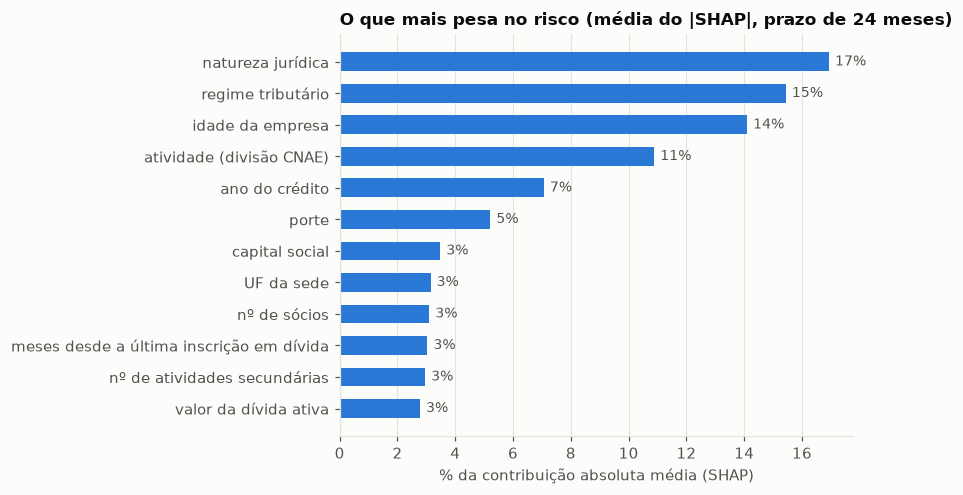

In [8]:
from consig_risk.modeling.data import prediction_pieces
from consig_risk.modeling.models import prepare_features
from consig_risk.modeling.spec import FEATURE_NAMES

# Importância = média do |SHAP| (log da taxa) em 20 mil empresas do teste, prazo de 24 meses.
# É a mesma medida das explicações do agent. A importância por ganho do LightGBM infla
# categóricas com muitos níveis (natureza jurídica, divisão CNAE), por isso não é usada.
amostra_shap = teste.sample(20_000, random_state=0).reset_index(drop=True)
pecas = prediction_pieces(amostra_shap, 24)
x = prepare_features(pecas, modelo.gbm.categories)[list(FEATURE_NAMES)]
shap = np.abs(modelo.gbm.booster.predict(x, pred_contrib=True)[:, :-1])
imp = pd.Series(shap.mean(axis=0), index=FEATURE_NAMES)
imp = (100 * imp / imp.sum()).sort_values(ascending=True).tail(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(imp))
ax.barh(y, imp.values, color=BLUE, height=0.6)
ax.set_yticks(y, [LABELS.get(n, n) for n in imp.index])
for yi, v in zip(y, imp.values):
    ax.annotate(
        f"{v:.0f}%",
        (v, yi),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=INK2,
    )
ax.set_xlabel("% da contribuição absoluta média (SHAP)")
ax.set_title("O que mais pesa no risco (média do |SHAP|, prazo de 24 meses)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Os quatro fatores que mais pesam são **natureza jurídica** (separa, por exemplo, condomínios e
associações, de risco muito baixo, do empresário individual), **regime tributário** (o sinal de
omissão fiscal), **idade** e **atividade econômica**. As fontes complementares aparecem pelo
regime tributário (ECF) e pelas variáveis de dívida ativa (PGFN).

A importância global mostra o que o modelo usa em média. Para o analista, o que interessa é **o
que pesa para aquela empresa**: o agent usa as contribuições SHAP de cada previsão (seção
abaixo). Um exemplo com um CNPJ público conhecido, o do Banco do Brasil (o mesmo do enunciado), e
uma empresa da amostra de teste com risco alto (sem identificação):

In [9]:
empresas = duckdb.sql(
    "SELECT * FROM 'data/processed/companies.parquet' WHERE cnpj_basico = '00000000'"
).df()
alto = teste.assign(r=1 - s_teste[:, 1]).sort_values("r").iloc[[-2000]]

for titulo, firma in [
    ("Banco do Brasil (foto 2026-10)", empresas),
    ("empresa de risco alto (teste, anônima)", alto),
]:
    s = modelo.survival(firma, (12, 24, 36, 60))[0]
    print(
        f"\n{titulo}: risco 12m {100 * (1 - s[0]):.1f}% · 24m {100 * (1 - s[1]):.1f}% · 36m {100 * (1 - s[2]):.1f}% · 60m {100 * (1 - s[3]):.1f}%"
    )
    for d in modelo.drivers(firma, horizon=24, top=5):
        efeito = "aumenta" if d.contribution > 0 else "reduz"
        print(f"   {efeito} o risco ×{np.exp(abs(d.contribution)):.2f}  ·  {d.label} = {d.value}")


Banco do Brasil (foto 2026-10): risco 12m 1.0% · 24m 2.0% · 36m 3.5% · 60m 6.6%
   reduz o risco ×2.00  ·  idade da empresa = 722
   reduz o risco ×1.70  ·  nº de filiais ativas = 5427
   reduz o risco ×1.45  ·  nº de sócios = 41
   reduz o risco ×1.29  ·  regime tributário = real
   aumenta o risco ×1.22  ·  capital social = 120000000000.0

empresa de risco alto (teste, anônima): risco 12m 72.6% · 24m 73.7% · 36m 74.7% · 60m 76.4%
   aumenta o risco ×2.99  ·  regime tributário = sem_ecf
   aumenta o risco ×1.18  ·  setor (seção CNAE) = K
   aumenta o risco ×1.15  ·  grupo de natureza jurídica = 3
   aumenta o risco ×1.12  ·  natureza jurídica = 3212
   reduz o risco ×1.10  ·  atividade (divisão CNAE) = 66


- Para o **Banco do Brasil**, o risco é baixo (cerca de 2% em 24 meses), puxado para baixo pela
  idade (60 anos), pelas milhares de filiais, pelo número de sócios e pelo Lucro Real. O capital
  social aparece "aumentando" o risco: R$ 120 bilhões está muito acima de qualquer valor do
  treino, e a árvore trata o caso como o maior capital visto. É exatamente o caso de valor fora da
  faixa que o agent deve sinalizar.
- Para a **empresa de risco alto**, o fator dominante é não ter entregue a ECF estando fora do
  Simples, que multiplica a taxa de saída por cerca de 3. O risco se concentra no primeiro ano: é
  o perfil de empresa que já parou e ainda não foi declarada inapta.

## 7. Sensibilidade: e se o evento fosse só a baixa?

A decisão de contar inaptidão como evento (EDA, seção 2) é a mais importante do projeto. Aqui o
mesmo GBM é treinado com o evento "só baixada", para ver quanto o risco e a separação mudam.

In [10]:
treino_b = treino.assign(evento=treino["tipo_evento"].eq("baixada"))
valid_b = valid.assign(evento=valid["tipo_evento"].eq("baixada"))
gbm_b = PiecewiseGBM().fit(mdata.expand_pieces(treino_b), cats, mdata.expand_pieces(valid_b))
sens = pd.DataFrame(
    [
        resumo("evento = qualquer saída (modelo final)", valid, candidatos[gbm5.name]),
        resumo("evento = só baixada", valid_b, gbm_b.survival(valid_b, EVALUATION_HORIZONS)),
    ]
).set_index("modelo")
display(
    sens[
        [
            "C-index",
            "AUC 12m",
            "AUC 24m",
            "previsto/observado 12m",
            "previsto/observado 24m",
            "previsto/observado 41m",
        ]
    ]
)

,C-index,AUC 12m,AUC 24m,previsto/observado 12m,previsto/observado 24m,previsto/observado 41m
modelo,,,,,,
evento = qualquer saída (modelo final),0.717,0.737,0.740,6.6% / 6.6%,13.1% / 12.9%,24.0% / 24.3%
evento = só baixada,0.687,0.691,0.690,3.9% / 3.9%,7.4% / 7.1%,11.8% / 11.1%


Com "só baixada", o risco cai para menos da metade e a separação piora: a baixa voluntária é
mais difícil de antecipar com dados cadastrais e fiscais do que o abandono (inaptidão), que deixa
rastros como falta de ECF e dívida ativa. Manter a inaptidão como evento é a escolha
conservadora e a mais informativa para o credor.

## Conclusões

| Decisão | Por quê |
|---|---|
| Exponencial por partes + LightGBM (Poisson) | Melhor separação entre os candidatos, com calibração equivalente à do GLM; não aprende o calendário dos lotes; extrapola com a idade |
| Cox descartado | Separa menos, subestima o risco e não permite extrapolar com a idade |
| GLM descartado como modelo final | Bem calibrado e interpretável, mas separa menos; fica como referência |
| ECF e PGFN mantidas | Cada uma melhora a separação, e juntas acrescentam ~0,03 de AUC (seção 3) |
| AUC ~0,74 | Modesta e esperada sem dados de faturamento ou folha; o risco é bem calibrado, que é o que o veredito usa; a separação é melhor (~0,8) no perfil típico de empregador |

**Limitações:** risco acima de 36 meses é extrapolado; o modelo distingue pouco entre empresas com
menos de 3 anos; valores muito acima da faixa do treino são tratados como o maior valor visto;
duas fotos não mostram eventos entre elas; o risco de demissão do funcionário não é modelado.